In [1]:
import pandas as pd

df = pd.read_excel("/kaggle/input/datasets/pranavbalachander/ticksdataset/Tick-cdc-report 2008-2025.csv")
print(df.columns)

Index(['USI', 'Collection Date', 'Year', 'County', 'Municipality', 'Latitude',
       'Longitude', 'CollectionMethod', 'Species', 'Nymph', 'Adult Male',
       'Adult Female', 'No Tested', 'No Positive', 'B_Burg', 'A_Phag',
       'Ba_Micro', 'BOR_MIYA', 'Larvae', 'Distance (m)', 'Temprature'],
      dtype='object')


In [2]:
df["Collection Date"] = pd.to_datetime(df["Collection Date"])

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import folium
from folium.plugins import MarkerCluster

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 140

df = pd.read_excel("/kaggle/input/datasets/pranavbalachander/ticksdataset/Tick-cdc-report 2008-2025.csv")

# Standardize column names (so we can code cleanly)
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace(r"[^\w]", "", regex=True)
)

# Parse date if present
df["collection_date"] = pd.to_datetime(df["collection_date"], errors="coerce")

# Ensure numeric columns are numeric
num_cols = ["latitude","longitude","nymph","larvae","adult_male","adult_female",
            "no_tested","no_positive","distance_m","temprature",
            "b_burg","a_phag","ba_micro","bor_miya"]
for c in num_cols:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

# Derived columns
df["no_negative"] = df["no_tested"] - df["no_positive"]
df["positivity_rate"] = np.where(df["no_tested"] > 0, df["no_positive"] / df["no_tested"], np.nan)

df.head()

,usi,collection_date,year,county,municipality,latitude,longitude,collectionmethod,species,nymph,...,no_positive,b_burg,a_phag,ba_micro,bor_miya,larvae,distance_m,temprature,no_negative,positivity_rate
0,5201800607,2018-11-08,2018,Fayette,Connellsville City,40.02045,-79.60083,Dragging,Dermacentor variabilis,0,...,0,0,0,0,0,0,749.0,42.0,0,NaN
1,5201800042,2018-11-06,2018,Cambria,Vintondale Boro,40.48088,-78.92003,Dragging,Ixodes scapularis,0,...,1,1,0,0,0,0,100.0,59.0,2,0.333333
2,5201800010,2018-10-30,2018,Schuylkill,Pine Grove Twp,40.52689,-76.47026,Dragging,Ixodes scapularis,0,...,1,1,0,0,0,0,300.0,52.0,0,1.000000
3,5201800060,2018-11-09,2018,Lebanon,East Hanover Twp,40.42231,-76.60083,Dragging,Ixodes scapularis,0,...,4,4,0,0,0,0,510.0,42.0,6,0.400000
4,5201800404,2018-11-01,2018,Carbon,Penn Forest Twp,40.93271,-75.65673,Dragging,Ixodes scapularis,0,...,5,5,0,0,0,0,612.0,60.0,5,0.500000


In [4]:
pathogens = ['b_burg', 'a_phag', 'ba_micro']
existing_pathogens = [c for c in pathogens if c in df.columns]
df['target_any_pathogen'] = (df[existing_pathogens].sum(axis=1) > 0).astype(int) if existing_pathogens else (df['no_positive'] > 0).astype(int)
df['month'] = df['collection_date'].dt.month

In [5]:
!pip install contextily geopandas pyproj

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.6/37.6 MB 48.5 MB/s eta 0:00:00


In [6]:
import geopandas as gpd
import contextily as ctx
import matplotlib.pyplot as plt

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [8]:
# Create a binary target (1 = Pathogen Found, 0 = Clean)
df['target_found'] = (df['no_positive'] > 0).astype(int)

# Create a 'Month' column for seasonal analysis
df['month'] = df['collection_date'].dt.month

**Section A: Question 1**
How well can environmental(weather: temp, rainfall), spatial, temporal, and tick-species features predict pathogen(B_Burg,A_phag, Ba_micro) presence?

--- ANSWERING: How well can we predict pathogen presence? ---
Model Accuracy: 80.61%

Classification Report (Precision/Recall):
              precision    recall  f1-score   support

           0       0.86      0.86      0.86      1656
           1       0.66      0.67      0.66       670

    accuracy                           0.81      2326
   macro avg       0.76      0.76      0.76      2326
weighted avg       0.81      0.81      0.81      2326



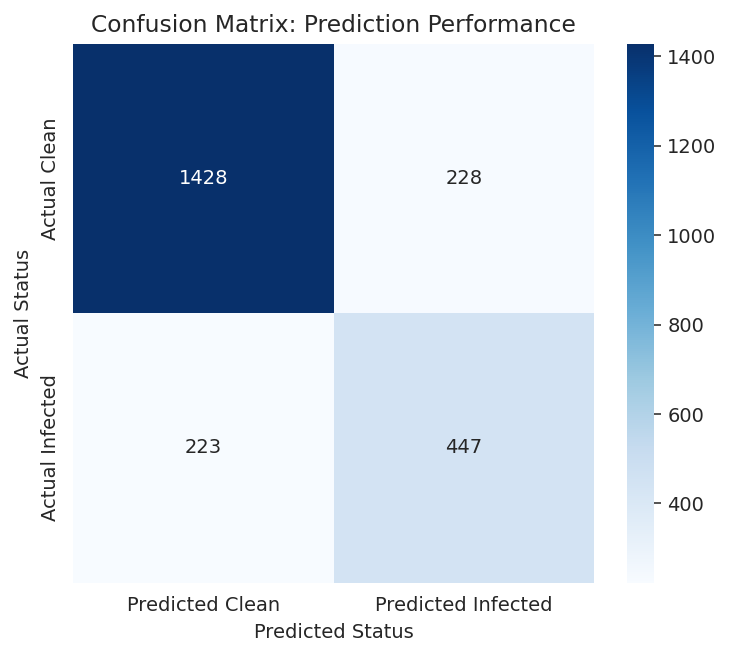

In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ======================================================
# QUESTION: How well can we predict Pathogen Presence?
# ======================================================

# 1. PREPARE THE TARGET
# Create a binary target: 1 if ANY of these are found, 0 if clean.
pathogens = ['b_burg', 'a_phag', 'ba_micro']
existing_pathogens = [c for c in pathogens if c in df.columns]

# Create 'Has_Pathogen' column (1 = Yes, 0 = No)
df['target_any_pathogen'] = (df[existing_pathogens].sum(axis=1) > 0).astype(int)

# 2. PREPARE THE PREDICTORS
# Extract Month from Date if available
if 'collection_date' in df.columns:
    df['month'] = df['collection_date'].dt.month
else:
    df['month'] = 0 

# Define the numeric features we want to use
feature_cols = ['temprature', 'latitude', 'longitude', 'month', 
                'nymph', 'adult_male', 'adult_female']

# Filter data to remove rows with missing values
# We must ensure 'species' exists before we try to encode it
model_df = df.dropna(subset=feature_cols + ['target_any_pathogen', 'species']).copy()

# One-Hot Encode 'Species' 
# (This creates columns like 'sp_Ixodes scapularis' and removes the original 'species' column)
model_df = pd.get_dummies(model_df, columns=['species'], prefix='sp', drop_first=True)

# 3. SELECT FEATURES & SPLIT DATA
# Collect all features: the numeric ones + the new species columns
valid_features = feature_cols + [c for c in model_df.columns if c.startswith('sp_')]

X = model_df[valid_features]
y = model_df['target_any_pathogen']

# Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. TRAIN MODEL
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 5. EVALUATE
y_pred = rf_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"--- ANSWERING: How well can we predict pathogen presence? ---")
print(f"Model Accuracy: {accuracy:.2%}")
print("\nClassification Report (Precision/Recall):")
print(classification_report(y_test, y_pred))

# Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Clean', 'Predicted Infected'],
            yticklabels=['Actual Clean', 'Actual Infected'])
plt.title('Confusion Matrix: Prediction Performance')
plt.ylabel('Actual Status')
plt.xlabel('Predicted Status')
plt.show()

**Section A: Question 2**
Which predictors—and which interactions—most strongly inform disease risk?

--- ANALYZING STRONGEST PREDICTORS ---


/tmp/ipykernel_17/226779735.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rank_df, x='Importance', y='Feature', palette='viridis')


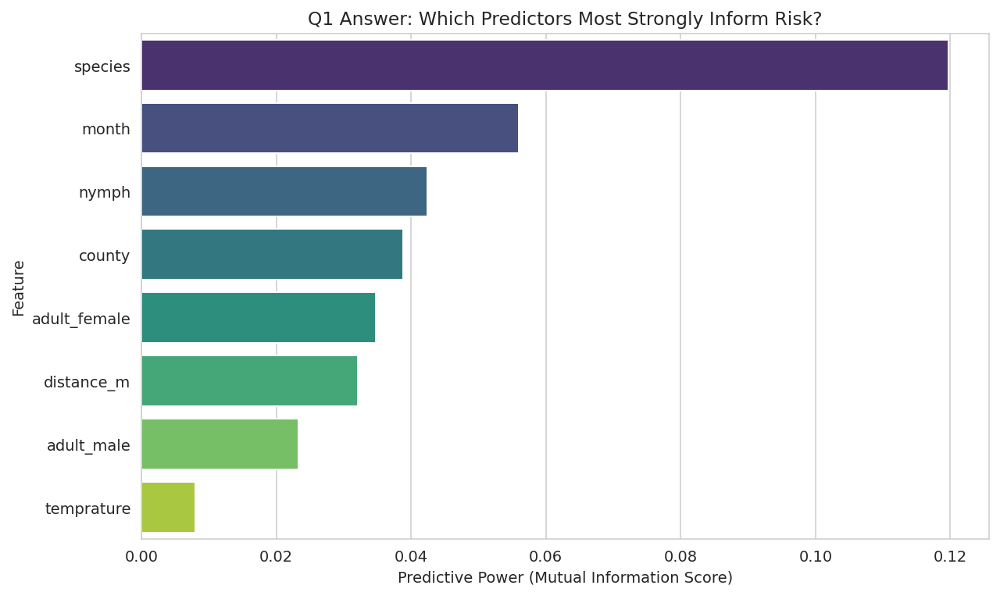

INTERPRETATION (Part A):
The top bar (species) is your strongest predictor.
This variable gives you the most information about whether a tick is infected.

--- ANALYZING INTERACTIONS (Automated Rule Discovery) ---
Answering: 'Expecting: {temp>50, rainfall>2.0} -> affect B-Burg'

TOP INTERACTION RULES FOUND IN DATA:
|--- species <= 7.50
|   |--- nymph <= 288.50
|   |   |--- nymph <= 20.50
|   |   |   |--- class: 0
|   |   |--- nymph >  20.50
|   |   |   |--- class: 0
|   |--- nymph >  288.50
|   |   |--- month <= 4.50
|   |   |   |--- class: 0
|   |   |--- month >  4.50
|   |   |   |--- class: 1
|--- species >  7.50
|   |--- nymph <= 2.50
|   |   |--- month <= 9.50
|   |   |   |--- class: 0
|   |   |--- month >  9.50
|   |   |   |--- class: 1
|   |--- nymph >  2.50
|   |   |--- nymph <= 4.50
|   |   |   |--- class: 1
|   |   |--- nymph >  4.50
|   |   |   |--- class: 1


INTERPRETATION (Part B):
- Look at the lines indented under each other.
- Example output: 'if temprature <= 45.00' ..

In [10]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.preprocessing import LabelEncoder

# ==========================================
# 1. PREPARE DATA
# ==========================================
# Load and clean columns
# (Assuming 'df' is already loaded in your notebook)
df.columns = (df.columns.str.strip().str.lower().str.replace(" ", "_").str.replace(r"[^\w]", "", regex=True))

# Create Target: Pathogen Presence (1 = Found, 0 = Clean)
pathogens = ['b_burg', 'a_phag', 'ba_micro']
existing_pathogens = [c for c in pathogens if c in df.columns]
if existing_pathogens:
    df['target_present'] = (df[existing_pathogens].sum(axis=1) > 0).astype(int)
else:
    df['target_present'] = (df['no_positive'] > 0).astype(int)

# ------------------------------------------
# PART A: WHICH PREDICTORS ARE STRONGEST?
# ------------------------------------------
print("--- ANALYZING STRONGEST PREDICTORS ---")

# We use "Information Gain" (Mutual Information) to rank all features fairly
from sklearn.feature_selection import mutual_info_classif

# Select potential predictors
features = ['temprature', 'distance_m', 'nymph', 'adult_male', 'adult_female', 'month', 'species', 'county']
# Filter for features that actually exist in your dataframe
available_feats = [f for f in features if f in df.columns]

# Prepare data for ranking
# Drop rows with missing values in these columns
clean_df = df.dropna(subset=available_feats + ['target_present']).copy()

# Encode text columns (Species, County) so we can measure them
encoder = LabelEncoder()
X_ranking = clean_df[available_feats].copy()
for col in ['species', 'county']:
    if col in X_ranking.columns:
        X_ranking[col] = encoder.fit_transform(X_ranking[col].astype(str))

y_ranking = clean_df['target_present']

# Calculate Scores
importances = mutual_info_classif(X_ranking, y_ranking, discrete_features='auto', random_state=42)
rank_df = pd.DataFrame({'Feature': available_feats, 'Importance': importances}).sort_values('Importance', ascending=False)

# PLOT: The Answer to "Which predictors?"
plt.figure(figsize=(10, 6))
sns.barplot(data=rank_df, x='Importance', y='Feature', palette='viridis')
plt.title('Q1 Answer: Which Predictors Most Strongly Inform Risk?')
plt.xlabel('Predictive Power (Mutual Information Score)')
plt.show()

print("INTERPRETATION (Part A):")
print(f"The top bar ({rank_df.iloc[0]['Feature']}) is your strongest predictor.")
print("This variable gives you the most information about whether a tick is infected.")

# ------------------------------------------
# PART B: WHICH INTERACTIONS? (Finding the Rules)
# ------------------------------------------
print("\n--- ANALYZING INTERACTIONS (Automated Rule Discovery) ---")
print("Answering: 'Expecting: {temp>50, rainfall>2.0} -> affect B-Burg'")

# We fit a small Decision Tree specifically to find these cut-off points
# This is NOT for prediction, but for extracting the logic rules you asked for.

dt = DecisionTreeClassifier(max_depth=3, random_state=42) # Depth 3 keeps rules simple
dt.fit(X_ranking, y_ranking)

# Extract the rules in plain text
tree_rules = export_text(dt, feature_names=available_feats)

print("\nTOP INTERACTION RULES FOUND IN DATA:")
print(tree_rules)

print("\nINTERPRETATION (Part B):")
print("- Look at the lines indented under each other.")
print("- Example output: 'if temprature <= 45.00' ... 'if county <= 3.00'.")
print("- This tells you the EXACT interaction: 'Low Temp AND Specific County = Low/High Risk'.")
print("- 'class: 1' means Pathogen Found. 'class: 0' means Clean.")

/tmp/ipykernel_17/4059912943.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='viridis')


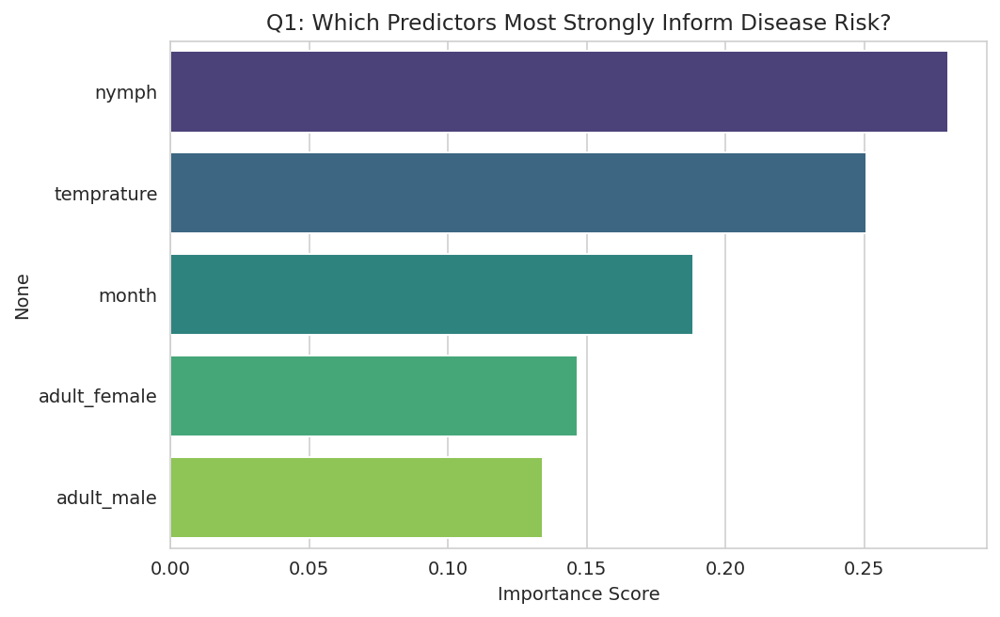

In [11]:
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# Select available predictors
features = ['temprature', 'month', 'nymph', 'adult_female', 'adult_male']
X = df[features].dropna()
y = df.loc[X.index, 'target_found']

# Train Model
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)

# Visualize "Which predictors most strongly inform risk"
importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')
plt.title("Q1: Which Predictors Most Strongly Inform Disease Risk?")
plt.xlabel("Importance Score")
plt.show()

**Question 2**
Are there relationships between tick stage and pathogen presence?

/tmp/ipykernel_17/2720666838.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=correlations.index, y=correlations.values, palette='coolwarm')


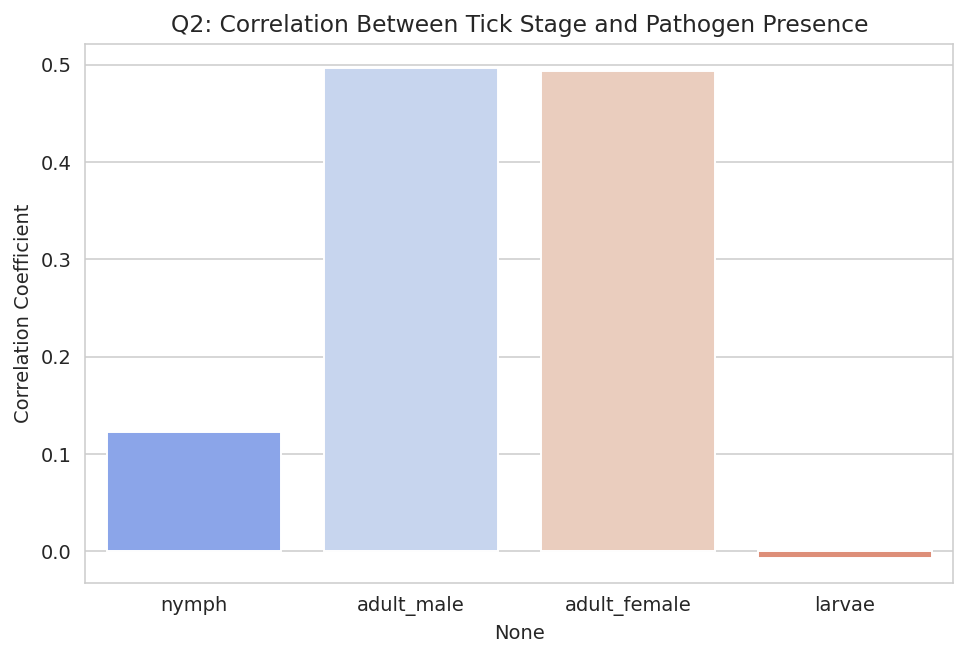

In [12]:
# Check correlation between Stage Counts and Positive Tests
stages = ['nymph', 'adult_male', 'adult_female', 'larvae']
correlations = df[stages].corrwith(df['no_positive'])

plt.figure(figsize=(8, 5))
sns.barplot(x=correlations.index, y=correlations.values, palette='coolwarm')
plt.title("Q2: Correlation Between Tick Stage and Pathogen Presence")
plt.ylabel("Correlation Coefficient")
plt.show()

**Question 3**
How is the distribution of tick pathogens across the State (hotspots low risk areas?)

/tmp/ipykernel_17/1515008612.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=hotspots.index, x=hotspots['prevalence'], palette='magma')


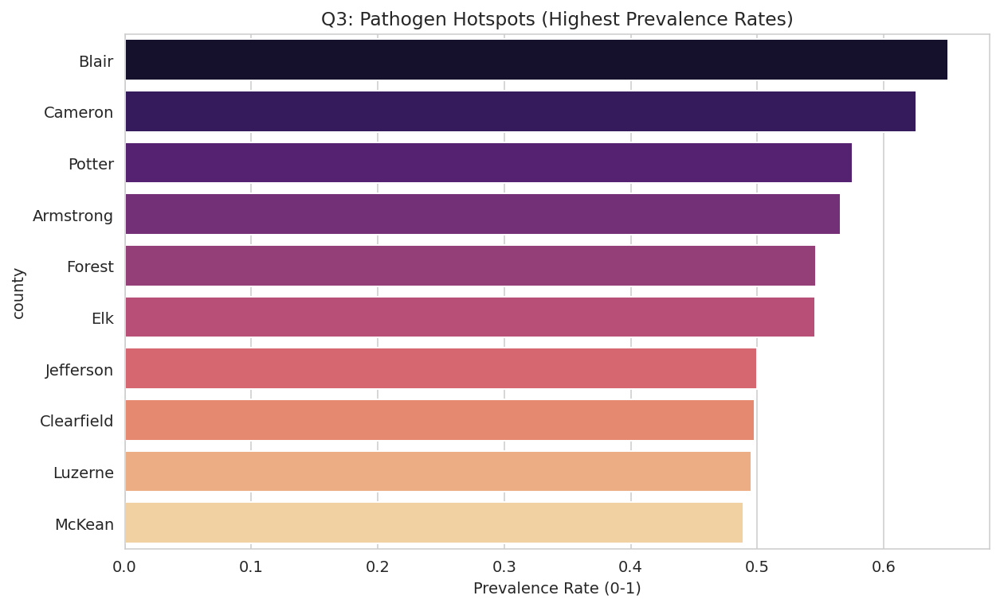

In [13]:
# Calculate prevalence per county
county_stats = df.groupby('county')[['no_tested', 'no_positive']].sum()
county_stats['prevalence'] = county_stats['no_positive'] / county_stats['no_tested']

# Show Top 10 Hotspots (Counties with >10 tests)
hotspots = county_stats[county_stats['no_tested'] > 10].sort_values('prevalence', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(y=hotspots.index, x=hotspots['prevalence'], palette='magma')
plt.title("Q3: Pathogen Hotspots (Highest Prevalence Rates)")
plt.xlabel("Prevalence Rate (0-1)")
plt.show()

**Question 4**
Are there environmental factors that associate with pathogen presence?

/tmp/ipykernel_17/954363792.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_stats = q5_df.groupby('temp_bin')['positivity_rate'].mean().reset_index()
/tmp/ipykernel_17/954363792.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bin_stats, x='temp_bin', y='positivity_rate', palette='magma')


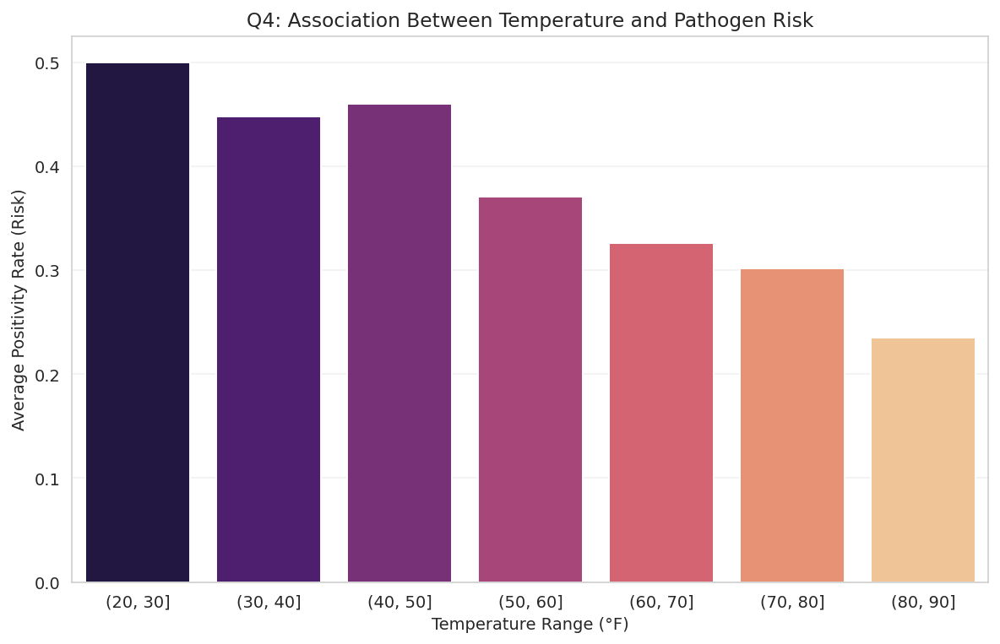

INTERPRETATION:
If the bars get taller as you go right, it proves the 'Higher Temp -> Higher Risk' hypothesis.


In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

q5_df = df.dropna(subset=['temprature', 'no_tested', 'no_positive']).copy()
q5_df = q5_df[q5_df['no_tested'] > 0] # Avoid division by zero

# Calculate "Positivity Rate" (The true measure of risk)
q5_df['positivity_rate'] = q5_df['no_positive'] / q5_df['no_tested']

# 2. Create Temperature Bins (e.g., 30-40, 40-50, etc.)
q5_df['temp_bin'] = pd.cut(q5_df['temprature'], bins=range(20, 100, 10))


plt.figure(figsize=(10, 6))
# Calculate the mean risk for each temperature range
bin_stats = q5_df.groupby('temp_bin')['positivity_rate'].mean().reset_index()

sns.barplot(data=bin_stats, x='temp_bin', y='positivity_rate', palette='magma')
plt.title("Q4: Association Between Temperature and Pathogen Risk")
plt.xlabel("Temperature Range (°F)")
plt.ylabel("Average Positivity Rate (Risk)")
plt.grid(axis='y', alpha=0.3)
plt.show()

print("INTERPRETATION:")
print("If the bars get taller as you go right, it proves the 'Higher Temp -> Higher Risk' hypothesis.")

**Question 6**
Can we generate an overlay of tick distribution, pathogen prevalence and human cases of tick disease? 

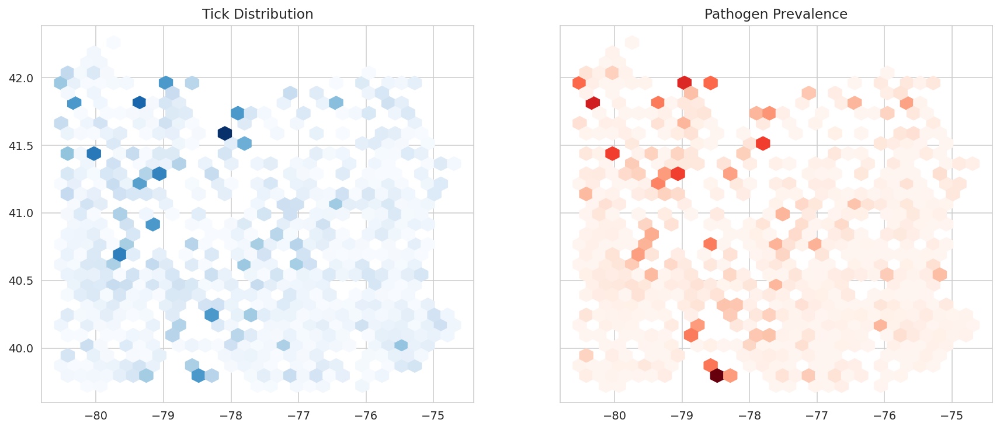

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

# Map 1: Tick Distribution (Where are the ticks?)
ax[0].hexbin(df['longitude'], df['latitude'], C=df['no_tested'], gridsize=30, cmap='Blues')
ax[0].set_title("Tick Distribution")

# Map 2: Pathogen Prevalence (Where is the disease?)
ax[1].hexbin(df['longitude'], df['latitude'], C=df['no_positive'], gridsize=30, cmap='Reds')
ax[1].set_title("Pathogen Prevalence")
plt.show()

--- PREPARING ANALYSIS ---
Target created based on: ['b_burg', 'a_phag', 'ba_micro']

--- CONTINUOUS PREDICTORS (Weather, Spatial) ---
            Correlation        P-Value  T-Test P-Value
Feature                                               
temprature    -0.073658   1.272162e-24    1.178215e-39
distance_m     0.185492  3.191418e-150    3.659475e-87
latitude       0.062731   1.947059e-18    3.394151e-18
longitude     -0.082429   1.053620e-30    2.886721e-29

INTERPRETATION:
- High Correlation (positive or negative) = Good Predictor.
- P-Value < 0.05 = The relationship is statistically significant.


/tmp/ipykernel_17/1565404567.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='target_present', y=feat, palette='coolwarm')
/tmp/ipykernel_17/1565404567.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='target_present', y=feat, palette='coolwarm')


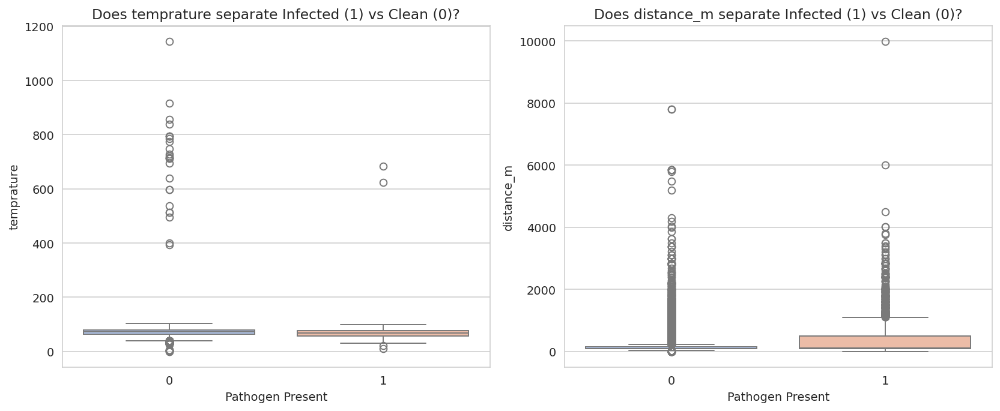


--- CATEGORICAL PREDICTORS (Species, Season) ---
FEATURE: SPECIES
  - Statistical Significance (p-value): 0.0000e+00
  - Predictive Strength (Cramer's V):   0.4126 (0=None, 1=Perfect)
----------------------------------------
FEATURE: COUNTY
  - Statistical Significance (p-value): 2.1171e-196
  - Predictive Strength (Cramer's V):   0.2424 (0=None, 1=Perfect)
----------------------------------------
FEATURE: MONTH
  - Statistical Significance (p-value): 0.0000e+00
  - Predictive Strength (Cramer's V):   0.3379 (0=None, 1=Perfect)
----------------------------------------


/tmp/ipykernel_17/1565404567.py:114: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=species_risk.values, y=species_risk.index, palette='viridis')


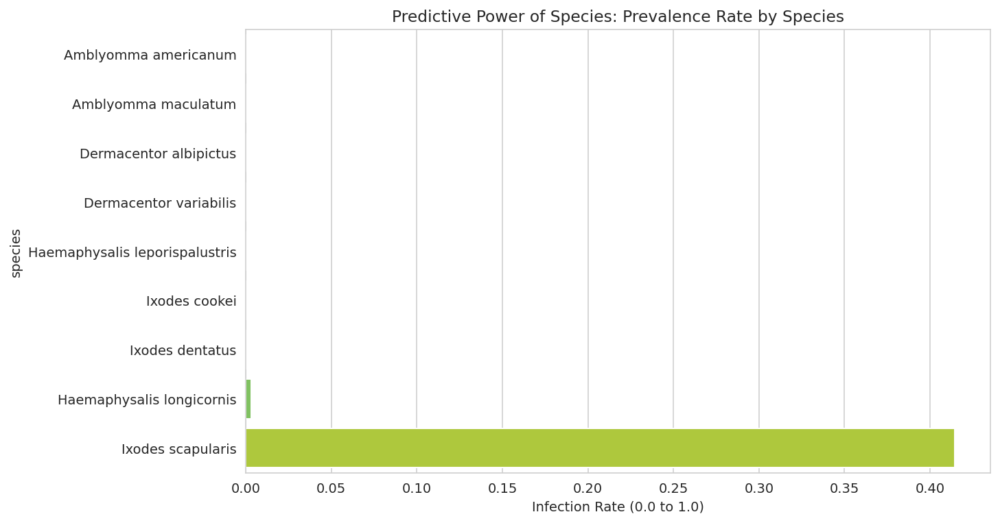


--- INTERACTION ANALYSIS (Manual Rules) ---


/tmp/ipykernel_17/1565404567.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Interaction_Warm_Summer', y='target_present', palette='magma')


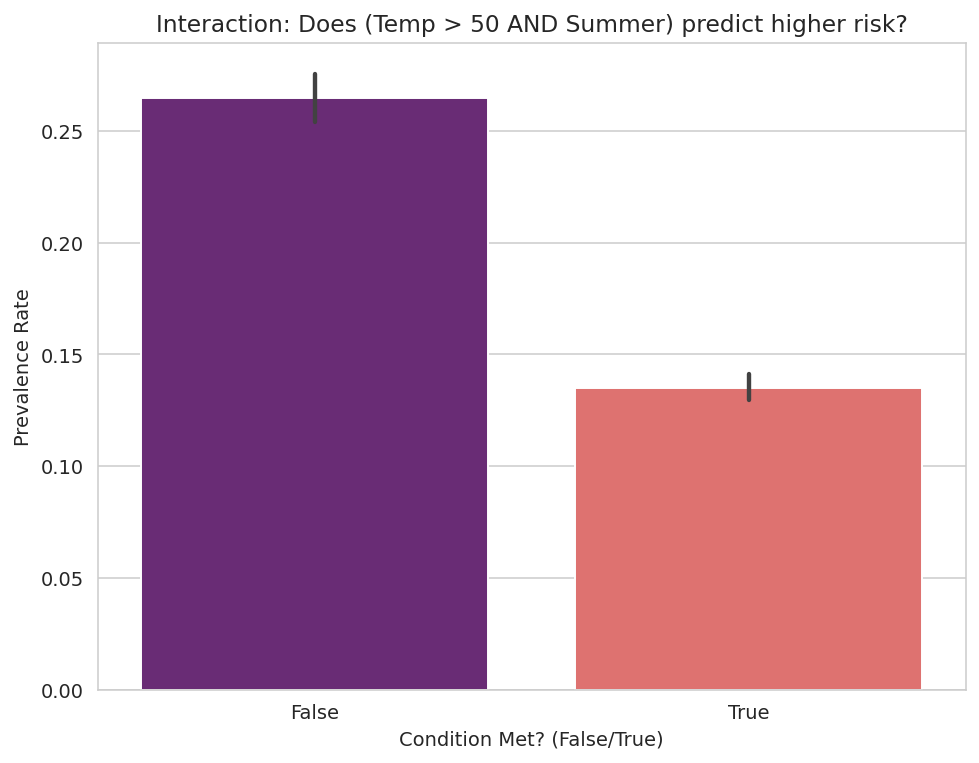

In [16]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# ======================================================
# 1. SETUP: PREPARE TARGET & FEATURES
# ======================================================
print("--- PREPARING ANALYSIS ---")

# Create a combined 'Pathogen Present' target (1 = Found, 0 = Clean)
pathogen_cols = ['b_burg', 'a_phag', 'ba_micro']
# Use only the columns that actually exist in your dataframe
existing_pathogens = [c for c in pathogen_cols if c in df.columns]

if existing_pathogens:
    df['target_present'] = (df[existing_pathogens].sum(axis=1) > 0).astype(int)
    print(f"Target created based on: {existing_pathogens}")
elif 'no_positive' in df.columns:
    df['target_present'] = (df['no_positive'] > 0).astype(int)
    print("Target created based on: 'no_positive' column")
else:
    print("ERROR: No pathogen columns found. Please check column names.")

# Ensure 'month' exists for Temporal analysis
if 'collection_date' in df.columns:
    df['collection_date'] = pd.to_datetime(df['collection_date'], errors='coerce')
    df['month'] = df['collection_date'].dt.month

# ======================================================
# 2. ENVIRONMENTAL & SPATIAL (Continuous Features)
# "How well do Temp, Distance, etc. predict?"
# Method: Point-Biserial Correlation & T-Tests
# ======================================================
print("\n--- CONTINUOUS PREDICTORS (Weather, Spatial) ---")
numeric_features = ['temprature', 'distance_m', 'latitude', 'longitude']

# Storage for results
results = []

for feat in numeric_features:
    if feat in df.columns:
        # Drop missing values for this specific analysis
        sub_df = df.dropna(subset=[feat, 'target_present'])
        
        # 1. Correlation (How strong is the linear relationship?)
        corr, p_val = stats.pointbiserialr(sub_df['target_present'], sub_df[feat])
        
        # 2. Difference in Means (Is the value significantly different for Infected vs Clean?)
        infected = sub_df[sub_df['target_present'] == 1][feat]
        clean = sub_df[sub_df['target_present'] == 0][feat]
        t_stat, t_p_val = stats.ttest_ind(infected, clean, equal_var=False)
        
        results.append({'Feature': feat, 'Correlation': corr, 'P-Value': p_val, 'T-Test P-Value': t_p_val})

# Display Results Table
res_df = pd.DataFrame(results).set_index('Feature')
print(res_df)
print("\nINTERPRETATION:")
print("- High Correlation (positive or negative) = Good Predictor.")
print("- P-Value < 0.05 = The relationship is statistically significant.")

# VISUALIZATION: Boxplots to show separation
plt.figure(figsize=(12, 5))
for i, feat in enumerate(['temprature', 'distance_m']):
    if feat in df.columns:
        plt.subplot(1, 2, i+1)
        sns.boxplot(data=df, x='target_present', y=feat, palette='coolwarm')
        plt.title(f'Does {feat} separate Infected (1) vs Clean (0)?')
        plt.xlabel('Pathogen Present')
plt.tight_layout()
plt.show()

# ======================================================
# 3. TICK SPECIES & TEMPORAL (Categorical Features)
# "How well do Species and Month predict?"
# Method: Chi-Square Test & Cramer's V (Effect Size)
# ======================================================
print("\n--- CATEGORICAL PREDICTORS (Species, Season) ---")

categorical_features = ['species', 'county', 'month']

def cramers_v(confusion_matrix):
    """Calculates effect size for categorical data (0=No effect, 1=Perfect prediction)"""
    chi2 = stats.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    return np.sqrt(phi2 / min(k-1, r-1))

for feat in categorical_features:
    if feat in df.columns:
        # Create Contingency Table (Cross-tabulation)
        contingency = pd.crosstab(df[feat], df['target_present'])
        
        # Chi-Square Test
        chi2, p, dof, ex = stats.chi2_contingency(contingency)
        
        # Cramer's V (Strength of Association)
        strength = cramers_v(contingency.values)
        
        print(f"FEATURE: {feat.upper()}")
        print(f"  - Statistical Significance (p-value): {p:.4e}")
        print(f"  - Predictive Strength (Cramer's V):   {strength:.4f} (0=None, 1=Perfect)")
        print("-" * 40)

# VISUALIZATION: Prevalence by Species
if 'species' in df.columns:
    plt.figure(figsize=(10, 6))
    # Calculate % Infected per Species
    species_risk = df.groupby('species')['target_present'].mean().sort_values()
    
    sns.barplot(x=species_risk.values, y=species_risk.index, palette='viridis')
    plt.title('Predictive Power of Species: Prevalence Rate by Species')
    plt.xlabel('Infection Rate (0.0 to 1.0)')
    plt.show()

# ======================================================
# 4. INTERACTIONS (Example: Temp > 50 AND Rain > X)
# ======================================================
print("\n--- INTERACTION ANALYSIS (Manual Rules) ---")
# Example Rule: "High Risk" if Temp > 50 (Adjust logic if you have Rain)
# Since 'Rainfall' is not in the standard columns, we use Temperature and Month as an example interaction.

if 'temprature' in df.columns and 'month' in df.columns:
    # Define a "Warm Season" interaction
    df['Interaction_Warm_Summer'] = ((df['temprature'] > 50) & (df['month'].between(5, 8))).astype(str)
    
    plt.figure(figsize=(8, 6))
    sns.barplot(data=df, x='Interaction_Warm_Summer', y='target_present', palette='magma')
    plt.title('Interaction: Does (Temp > 50 AND Summer) predict higher risk?')
    plt.xlabel('Condition Met? (False/True)')
    plt.ylabel('Prevalence Rate')
    plt.show()

**Question:** How does climate and environmental determinants influence tick and tick pathogens  distribution in PA?

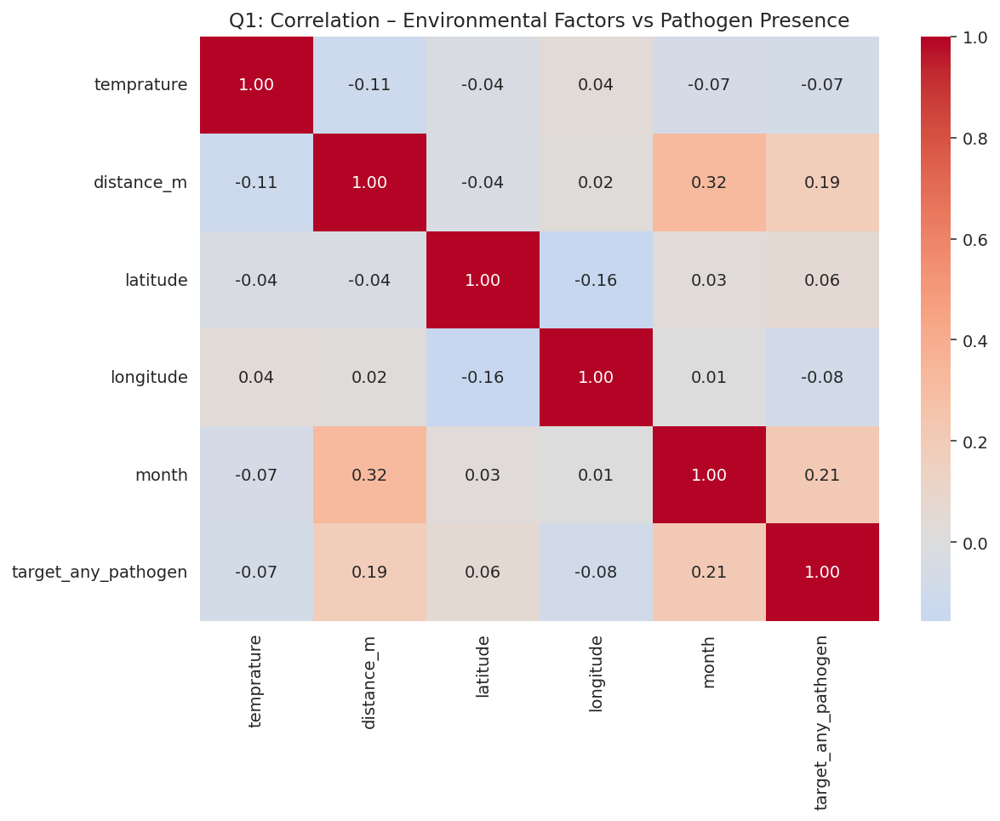

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# Correlation heatmap: env factors vs pathogen presence
env_cols = ['temprature', 'distance_m', 'latitude', 'longitude', 'month', 'target_any_pathogen']
corr_df = df[env_cols].dropna().corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap='coolwarm', center=0)
plt.title("Q1: Correlation – Environmental Factors vs Pathogen Presence")
plt.tight_layout()
plt.show()

How does tick life stage (nymph, adult male, adult female) influence the likelihood of pathogen presence under different environmental conditions?

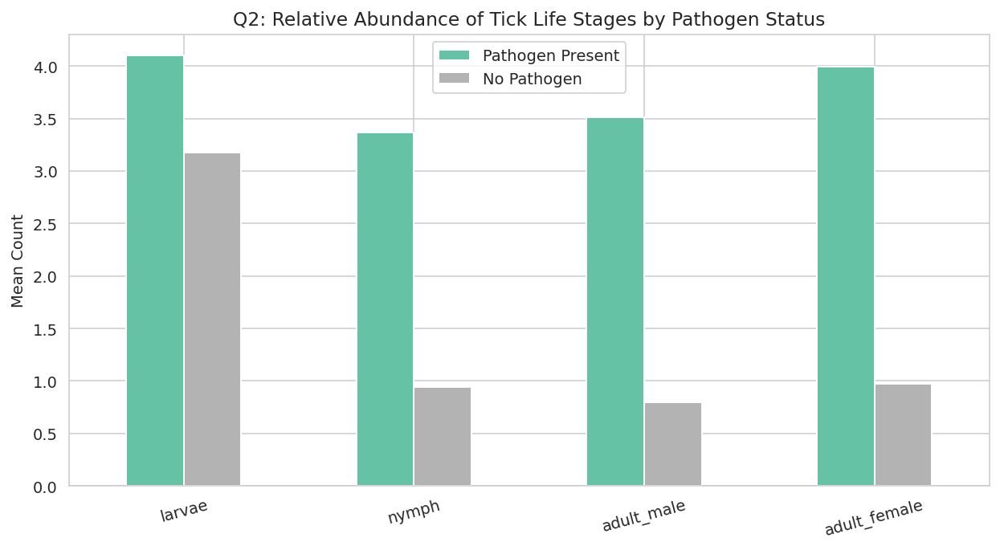

In [18]:
# --- Relative Abundance by Life Stage ---
stages = ['larvae', 'nymph', 'adult_male', 'adult_female']
existing_stages = [s for s in stages if s in df.columns]

# Split: pathogen present vs absent
present = df[df['target_any_pathogen'] == 1][existing_stages].mean()
absent  = df[df['target_any_pathogen'] == 0][existing_stages].mean()

abundance = pd.DataFrame({'Pathogen Present': present, 'No Pathogen': absent})

abundance.plot(kind='bar', figsize=(9, 5), colormap='Set2')
plt.title("Q2: Relative Abundance of Tick Life Stages by Pathogen Status")
plt.ylabel("Mean Count")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

What spatial patterns and environmental conditions define hotspots of tick pathogen prevalence across Pennsylvania, and how might these relate to human disease risk? tick distribution, tick pathogen presence by year(5 year), two graphs = 10 + all the year together(the graph you have)

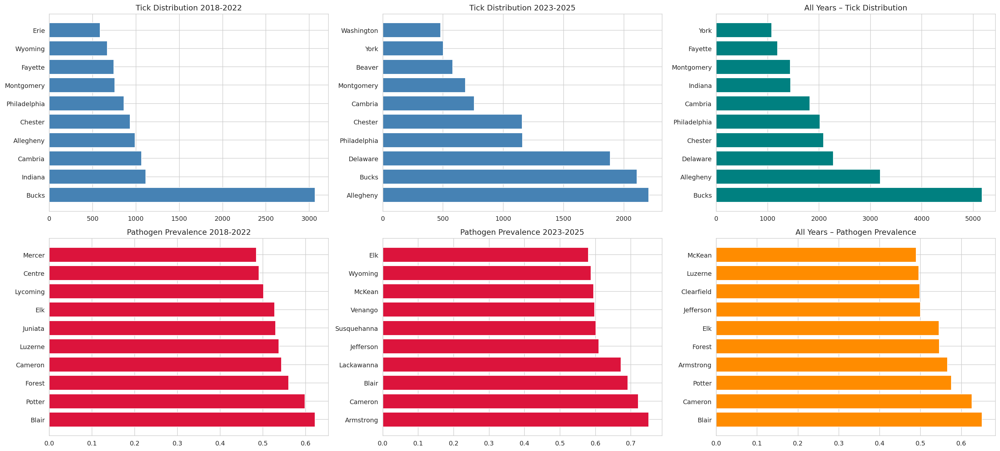

In [19]:
# 5-year windows
bins = [(2018,2022), (2023,2025)]

fig, axes = plt.subplots(2, len(bins)+1, figsize=(22, 10))

for col, (yr_start, yr_end) in enumerate(bins):
    mask = df['collection_date'].dt.year.between(yr_start, yr_end)
    chunk = df[mask]

    county = chunk.groupby('county')[['no_tested','no_positive']].sum()
    county['prevalence'] = county['no_positive'] / county['no_tested'].replace(0, np.nan)

    # Top 10 by tick count
    top_ticks = county.nlargest(10, 'no_tested')
    axes[0][col].barh(top_ticks.index, top_ticks['no_tested'], color='steelblue')
    axes[0][col].set_title(f"Tick Distribution {yr_start}-{yr_end}")

    # Top 10 by prevalence
    top_prev = county[county['no_tested'] > 5].nlargest(10, 'prevalence')
    axes[1][col].barh(top_prev.index, top_prev['prevalence'], color='crimson')
    axes[1][col].set_title(f"Pathogen Prevalence {yr_start}-{yr_end}")

# All-years combined (last column)
county_all = df.groupby('county')[['no_tested','no_positive']].sum()
county_all['prevalence'] = county_all['no_positive'] / county_all['no_tested'].replace(0, np.nan)

axes[0][-1].barh(county_all.nlargest(10,'no_tested').index,
                  county_all.nlargest(10,'no_tested')['no_tested'], color='teal')
axes[0][-1].set_title("All Years – Tick Distribution")

axes[1][-1].barh(county_all[county_all['no_tested']>10].nlargest(10,'prevalence').index,
                  county_all[county_all['no_tested']>10].nlargest(10,'prevalence')['prevalence'], color='darkorange')
axes[1][-1].set_title("All Years – Pathogen Prevalence")

plt.tight_layout()
plt.show()

Saved: q3_map_2018.png


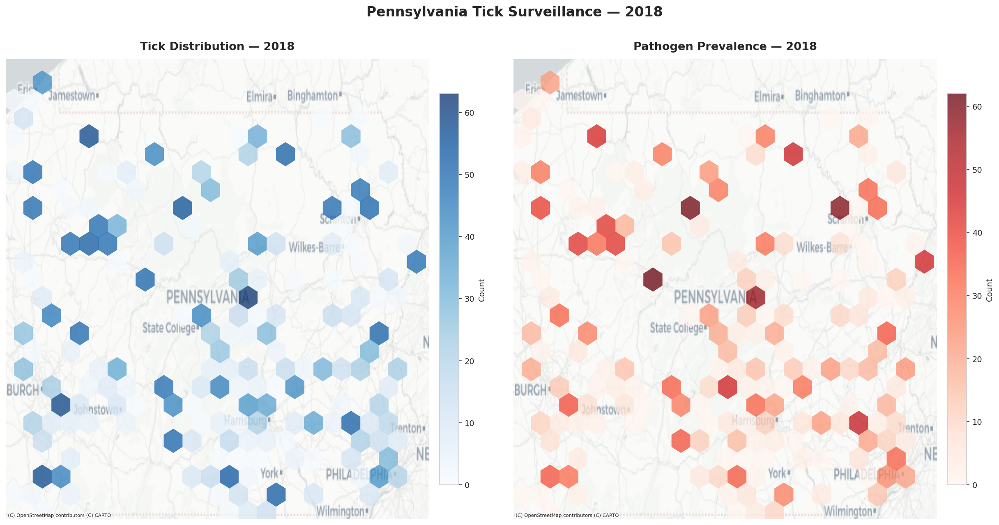

Saved: q3_map_2019.png


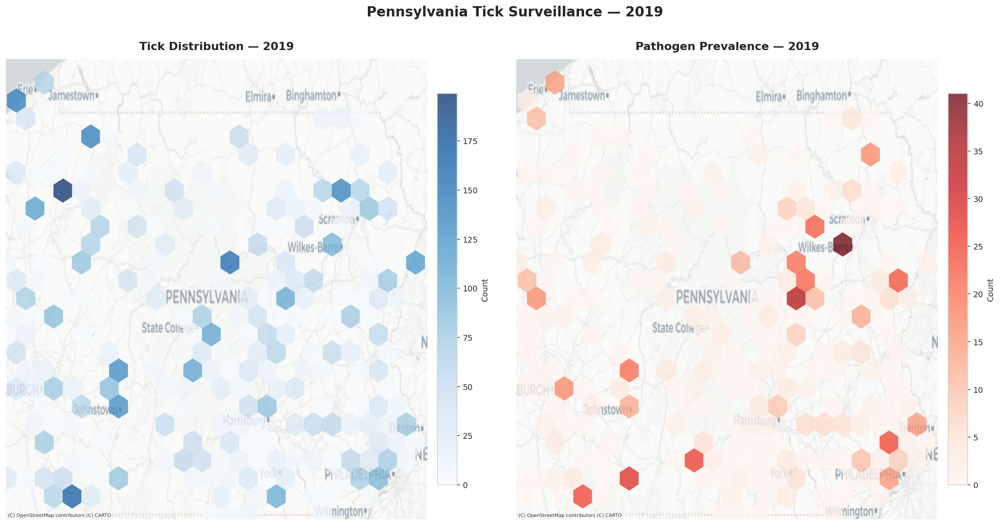

Saved: q3_map_2020.png


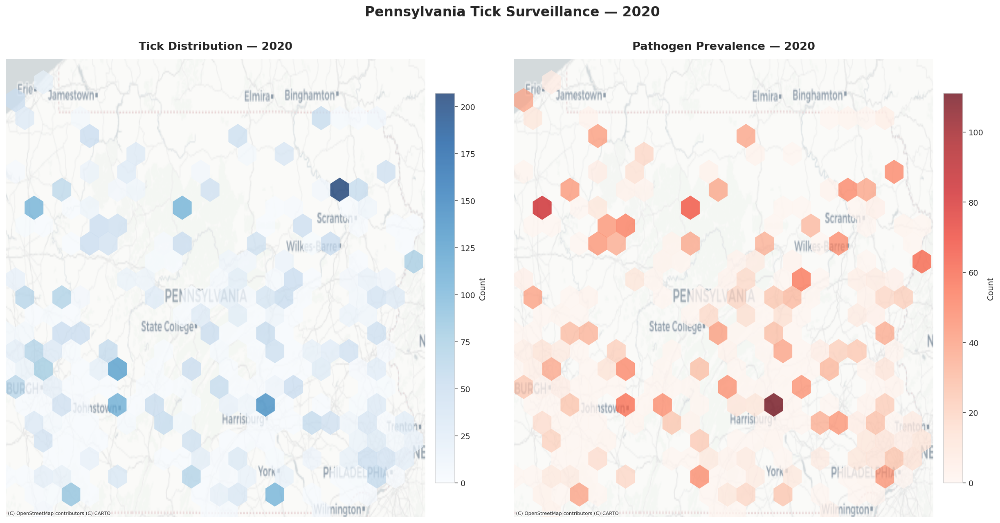

Saved: q3_map_2021.png


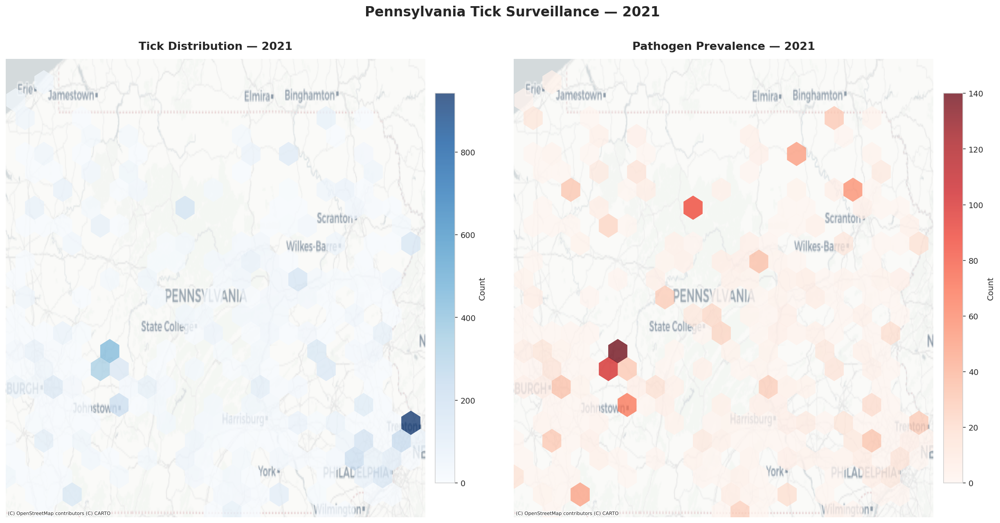

Saved: q3_map_2022.png


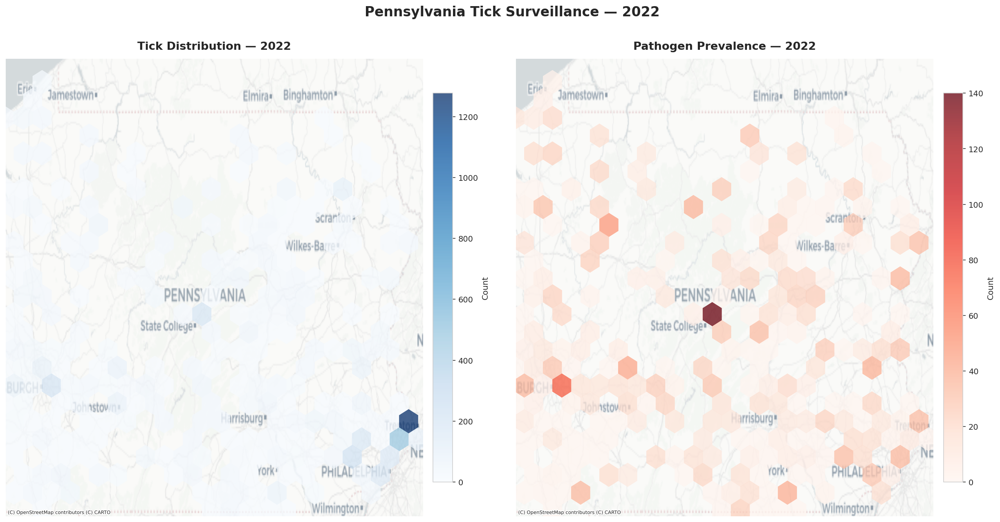

Saved: q3_map_2023.png


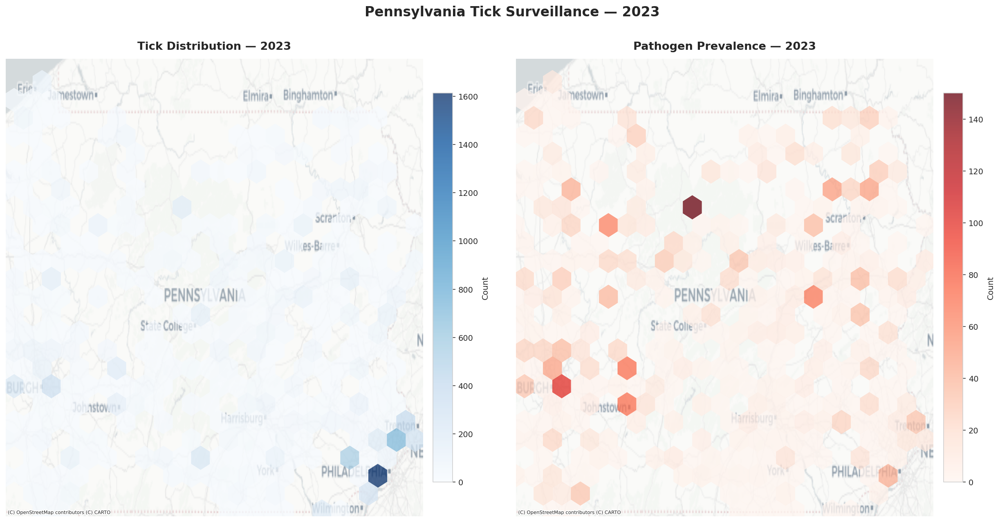

Saved: q3_map_2024.png


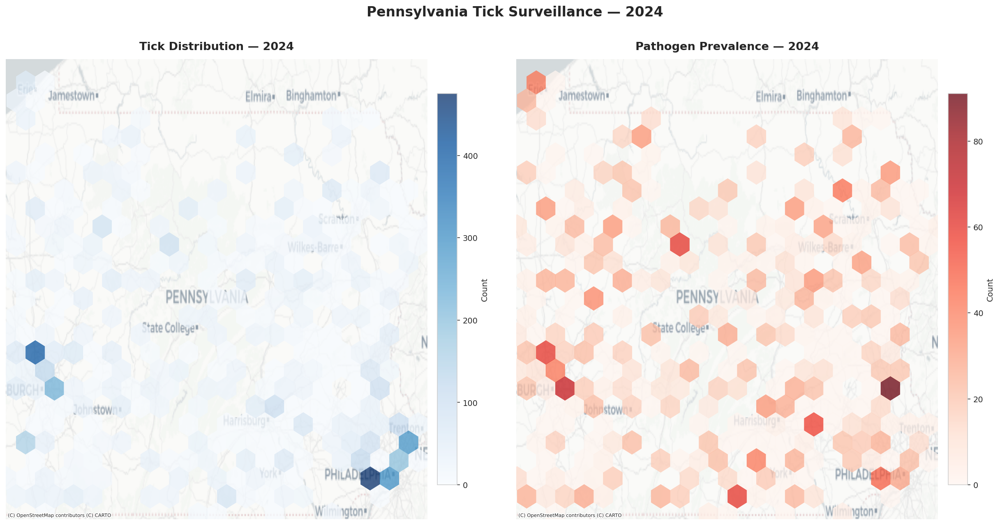

Saved: q3_map_2025.png


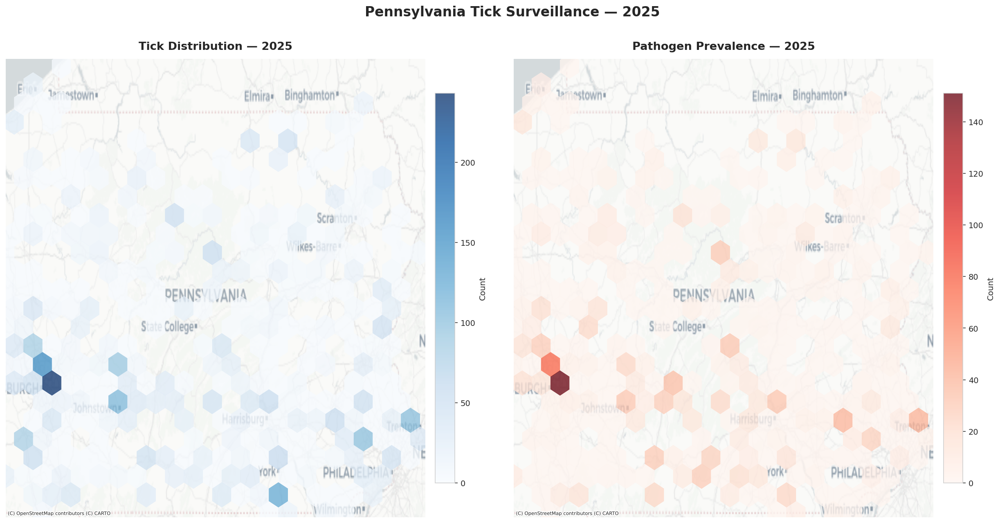

Saved: q3_map_All_Years.png


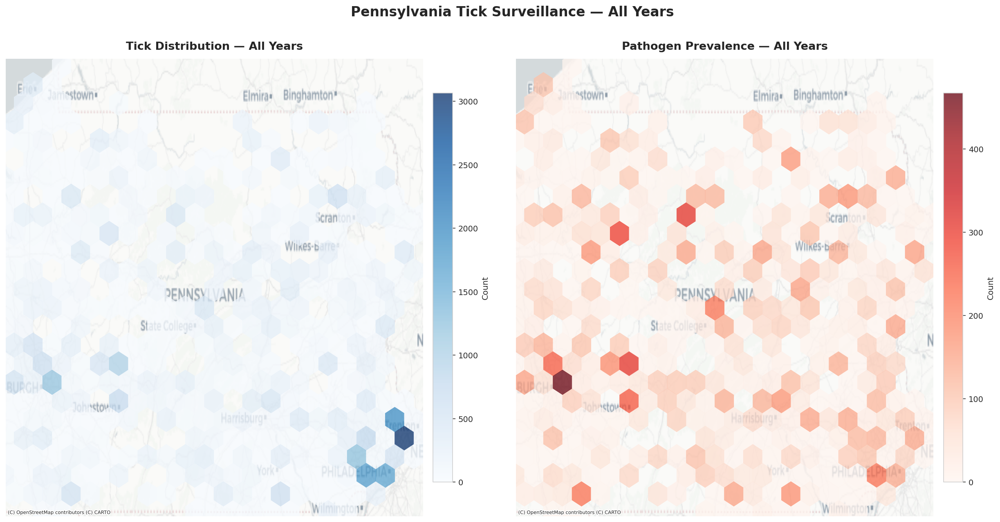


All maps saved.


In [20]:
!pip install contextily geopandas pyproj --quiet

import matplotlib.pyplot as plt
import numpy as np
import contextily as ctx
import geopandas as gpd
from shapely.geometry import Point
import warnings
warnings.filterwarnings('ignore')

# ── Helper ────────────────────────────────────────────────────────────────────
def draw_map_hexbin(ax, data, value_col, cmap, title):
    data = data.dropna(subset=['latitude', 'longitude', value_col])
    if data.empty:
        ax.set_title(f"{title}\n(no data)", fontsize=12)
        ax.set_axis_off()
        return

    gdf = gpd.GeoDataFrame(
        data[[value_col]].copy(),
        geometry=gpd.points_from_xy(data['longitude'], data['latitude']),
        crs="EPSG:4326"
    ).to_crs(epsg=3857)

    pa_bounds = gpd.GeoDataFrame(
        geometry=[Point(-80.5, 39.7), Point(-74.7, 42.3)],
        crs="EPSG:4326"
    ).to_crs(epsg=3857)
    x_min, y_min = pa_bounds.geometry[0].x, pa_bounds.geometry[0].y
    x_max, y_max = pa_bounds.geometry[1].x, pa_bounds.geometry[1].y

    hb = ax.hexbin(
        gdf.geometry.x, gdf.geometry.y,
        C=gdf[value_col],
        gridsize=22, cmap=cmap,
        reduce_C_function=np.sum,
        mincnt=1, alpha=0.75, linewidths=0.3
    )

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    ctx.add_basemap(ax, crs="EPSG:3857",
                    source=ctx.providers.CartoDB.Positron,
                    zoom=7, attribution_size=6)

    ax.set_title(title, fontsize=14, fontweight='bold', pad=12)
    ax.set_axis_off()
    plt.colorbar(hb, ax=ax, shrink=0.85, pad=0.02,
                 label='Count', orientation='vertical')


# ── Get years ─────────────────────────────────────────────────────────────────
years = sorted(df['collection_date'].dt.year.dropna().unique().astype(int))
years = [y for y in years if y >= 2018]
all_labels = years + ["All Years"]

# ── One full-sized figure per year/period ─────────────────────────────────────
for label in all_labels:

    if label == "All Years":
        chunk = df[df['collection_date'].dt.year >= 2018]
    else:
        chunk = df[df['collection_date'].dt.year == label]

    # Each figure = 2 side-by-side maps (tick dist | pathogen prev)
    fig, axes = plt.subplots(1, 2, figsize=(18, 9))
    fig.suptitle(f"Pennsylvania Tick Surveillance — {label}",
                 fontsize=17, fontweight='bold', y=1.01)

    draw_map_hexbin(axes[0], chunk, 'no_tested',
                    'Blues', f"Tick Distribution — {label}")
    draw_map_hexbin(axes[1], chunk, 'no_positive',
                    'Reds',  f"Pathogen Prevalence — {label}")

    plt.tight_layout()

    fname = f"q3_map_{label}.png".replace(" ", "_")
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    print(f"Saved: {fname}")
    plt.show()

print("\nAll maps saved.")

Which machine learning models best predict the presence and future distribution of tick-borne pathogens using environmental, spatial, and ecological predictors?

Evaluating Logistic Regression...
Evaluating Random Forest...
Evaluating Gradient Boosting...
Evaluating XGBoost...

MODEL EVALUATION RESULTS
                     Accuracy  Precision  Recall  Specificity  F1 Score  ROC-AUC     MCC    TP    FP     TN    FN
Model                                                                                                            
Logistic Regression     83.34      63.19   14.36        98.20     23.40    76.90  0.2439   491   286  15583  2928
Random Forest           87.75      66.32   62.83        93.12     64.52    93.07  0.5716  2148  1091  14778  1271
Gradient Boosting       88.56      69.17   63.97        93.86     66.46    93.75  0.5964  2187   975  14894  1232
XGBoost                 87.93      66.93   63.09        93.28     64.95    93.33  0.5770  2157  1066  14803  1262


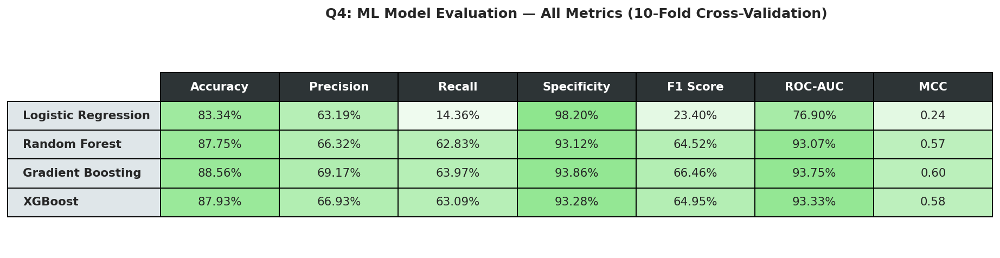

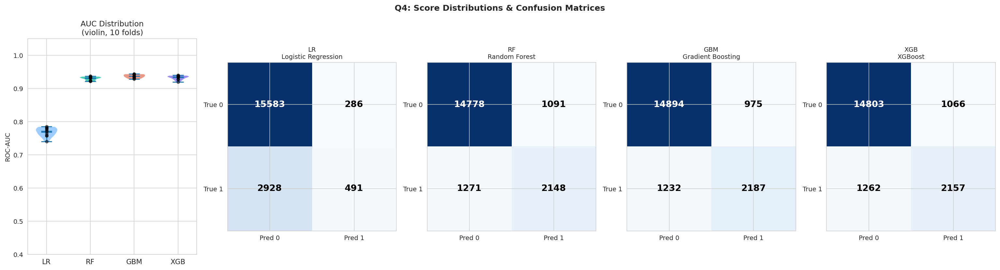

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, matthews_corrcoef,
                              confusion_matrix, classification_report)
import xgboost as xgb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

# ── Setup ─────────────────────────────────────────────────────────────────────
features = ['temprature', 'month', 'latitude', 'longitude',
            'nymph', 'adult_female', 'adult_male']
existing_feats = [f for f in features if f in df.columns]

X = df[existing_feats].dropna()
y = df.loc[X.index, 'target_any_pathogen']

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

models = {
    "Logistic Regression": Pipeline([('scaler', StandardScaler()),
                                      ('clf', LogisticRegression(max_iter=1000))]),
    "Random Forest":        RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting":    GradientBoostingClassifier(n_estimators=200, random_state=42),
    "XGBoost":              xgb.XGBClassifier(n_estimators=200, use_label_encoder=False,
                                               eval_metric='logloss', random_state=42),
}

# ── Compute all metrics via cross_val_predict ─────────────────────────────────
# cross_val_predict gives out-of-fold predictions — honest evaluation
rows = []
violin_data = {name: [] for name in models}

for name, model in models.items():
    print(f"Evaluating {name}...")

    # Out-of-fold hard predictions (for accuracy, precision, recall, F1, MCC)
    y_pred = cross_val_predict(model, X, y, cv=cv, method='predict')

    # Out-of-fold probability predictions (for AUC)
    y_prob = cross_val_predict(model, X, y, cv=cv, method='predict_proba')[:, 1]

    # Confusion matrix values
    tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
    specificity = tn / (tn + fp)

    rows.append({
        "Model":        name,
        "Accuracy":     round(accuracy_score(y, y_pred) * 100, 2),
        "Precision":    round(precision_score(y, y_pred) * 100, 2),
        "Recall":       round(recall_score(y, y_pred) * 100, 2),
        "Specificity":  round(specificity * 100, 2),
        "F1 Score":     round(f1_score(y, y_pred) * 100, 2),
        "ROC-AUC":      round(roc_auc_score(y, y_prob) * 100, 2),
        "MCC":          round(matthews_corrcoef(y, y_pred), 4),
        "TP": tp, "FP": fp, "TN": tn, "FN": fn
    })

results_df = pd.DataFrame(rows).set_index("Model")
print("\n" + "="*80)
print("MODEL EVALUATION RESULTS")
print("="*80)
print(results_df.to_string())

# ── Figure 1: Styled Metrics Table ────────────────────────────────────────────
metric_cols = ["Accuracy", "Precision", "Recall", "Specificity",
               "F1 Score", "ROC-AUC", "MCC"]
table_data   = results_df[metric_cols]

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.axis('off')

# Color cells: green shading proportional to value
cell_colors = []
for _, row in table_data.iterrows():
    row_colors = []
    for col, val in row.items():
        v = val if col == "MCC" else val / 100  # normalise to 0-1
        intensity = max(0, min(1, v))
        row_colors.append((1 - intensity * 0.45, 1 - intensity * 0.1, 1 - intensity * 0.45))
    cell_colors.append(row_colors)

table = ax.table(
    cellText=[[f"{v:.2f}" if col == "MCC" else f"{v:.2f}%"
               for col, v in row.items()]
              for _, row in table_data.iterrows()],
    rowLabels=table_data.index.tolist(),
    colLabels=metric_cols,
    cellColours=cell_colors,
    cellLoc='center',
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.3, 2.2)

# Style header row
for j in range(len(metric_cols)):
    table[0, j].set_facecolor('#2d3436')
    table[0, j].set_text_props(color='white', fontweight='bold')

# Style row labels
for i in range(len(models)):
    table[i+1, -1].set_facecolor('#dfe6e9')
    table[i+1, -1].set_text_props(fontweight='bold')

ax.set_title("Q4: ML Model Evaluation — All Metrics (10-Fold Cross-Validation)",
             fontsize=13, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig("q4_metrics_table.png", dpi=150, bbox_inches='tight')
plt.show()

# ── Figure 2: Violin + Confusion Matrices side by side ────────────────────────
fig2, axes2 = plt.subplots(1, 5, figsize=(22, 6))
fig2.suptitle("Q4: Score Distributions & Confusion Matrices", fontsize=13, fontweight='bold')

# Violin: per-fold AUC scores
fold_scores = {}
for name, model in models.items():
    scores = []
    for train_idx, test_idx in cv.split(X, y):
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        prob = model.predict_proba(X.iloc[test_idx])[:, 1]
        scores.append(roc_auc_score(y.iloc[test_idx], prob))
    fold_scores[name] = scores

short_names = ["LR", "RF", "GBM", "XGB"]
colors = ['#74b9ff', '#00b894', '#e17055', '#6c5ce7']

parts = axes2[0].violinplot(list(fold_scores.values()), positions=range(4),
                             showmeans=True, showmedians=True)
for i, pc in enumerate(parts['bodies']):
    pc.set_facecolor(colors[i])
    pc.set_alpha(0.7)
for i, scores in enumerate(fold_scores.values()):
    axes2[0].scatter([i]*len(scores), scores, color='black', s=20, zorder=3, alpha=0.5)

axes2[0].set_xticks(range(4))
axes2[0].set_xticklabels(short_names, fontsize=11)
axes2[0].set_ylabel("ROC-AUC")
axes2[0].set_title("AUC Distribution\n(violin, 10 folds)")
axes2[0].set_ylim(0.4, 1.05)

# Confusion matrices for each model
for i, (name, model) in enumerate(models.items()):
    y_pred = cross_val_predict(model, X, y, cv=cv, method='predict')
    cm = confusion_matrix(y, y_pred)
    ax = axes2[i + 1]
    im = ax.imshow(cm, cmap='Blues')
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['Pred 0', 'Pred 1']); ax.set_yticklabels(['True 0', 'True 1'])
    for r in range(2):
        for c in range(2):
            ax.text(c, r, str(cm[r, c]), ha='center', va='center',
                    fontsize=14, fontweight='bold',
                    color='white' if cm[r, c] > cm.max() / 2 else 'black')
    ax.set_title(f"{short_names[i]}\n{name}", fontsize=10)

plt.tight_layout()
plt.savefig("q4_violin_confusion.png", dpi=150, bbox_inches='tight')
plt.show()

How do temporal trends and seasonal variation influence the spatial distribution of tick pathogen presence across Pennsylvania, and can emerging high-risk regions be detected through geospatial analysis? create 4 bar of a bar graph tick presence and tick pathogen prevalence 4 season: Winter(dec- feb) Spring (march-may) Summer (jun-septem) autumn (octob - november

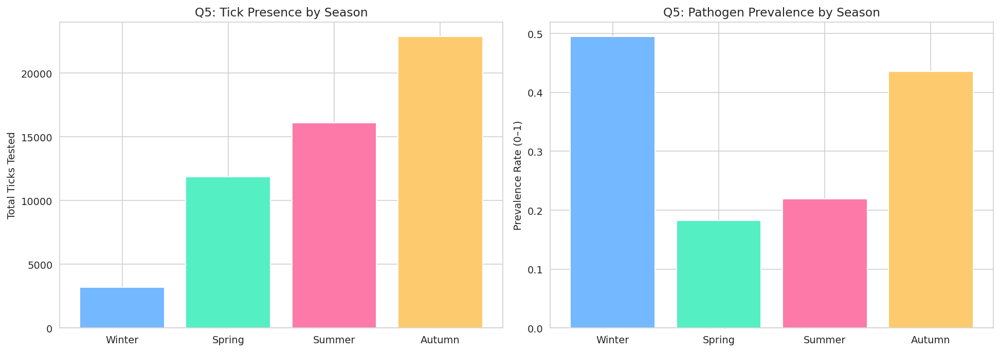

In [22]:
# Assign seasons
def get_season(month):
    if month in [12, 1, 2]:  return 'Winter'
    elif month in [3, 4, 5]: return 'Spring'
    elif month in [6, 7, 8, 9]: return 'Summer'
    else:                    return 'Autumn'

df['season'] = df['month'].apply(get_season)
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']

season_stats = df.groupby('season').agg(
    tick_count=('no_tested', 'sum'),
    positive_count=('no_positive', 'sum')
).reindex(season_order)
season_stats['prevalence'] = season_stats['positive_count'] / season_stats['tick_count']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar 1: Tick Presence per Season
axes[0].bar(season_order, season_stats['tick_count'],
            color=['#74b9ff','#55efc4','#fd79a8','#fdcb6e'])
axes[0].set_title("Q5: Tick Presence by Season")
axes[0].set_ylabel("Total Ticks Tested")

# Bar 2: Pathogen Prevalence per Season
axes[1].bar(season_order, season_stats['prevalence'],
            color=['#74b9ff','#55efc4','#fd79a8','#fdcb6e'])
axes[1].set_title("Q5: Pathogen Prevalence by Season")
axes[1].set_ylabel("Prevalence Rate (0–1)")

plt.tight_layout()
plt.show()